In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Task	1:	Dataset	preparation	

In [2]:
df= pd.read_csv("house_prices.csv")

In [4]:
df.head(5)

,area_sqft,bedrooms,bathrooms,house_age,price
0,1000,2,1,5,3500000
1,1500,3,2,3,5500000
2,2000,3,2,8,6500000
3,2500,4,3,2,9500000
4,1200,2,2,10,3800000


In [5]:
df.isna()

,area_sqft,bedrooms,bathrooms,house_age,price
0,False,False,False,False,False
1,False,False,False,False,False
2,False,False,False,False,False
3,False,False,False,False,False
4,False,False,False,False,False


In [6]:
df.isna().sum()

area_sqft    0
bedrooms     0
bathrooms    0
house_age    0
price        0
dtype: int64

Task	2:	Data	preprocessing	

In [7]:
X=df[["area_sqft","bedrooms","bathrooms","house_age"]]

In [8]:
X

,area_sqft,bedrooms,bathrooms,house_age
0,1000,2,1,5
1,1500,3,2,3
2,2000,3,2,8
3,2500,4,3,2
4,1200,2,2,10


In [9]:
y=df["price"]

In [10]:
y

0    3500000
1    5500000
2    6500000
3    9500000
4    3800000
Name: price, dtype: int64

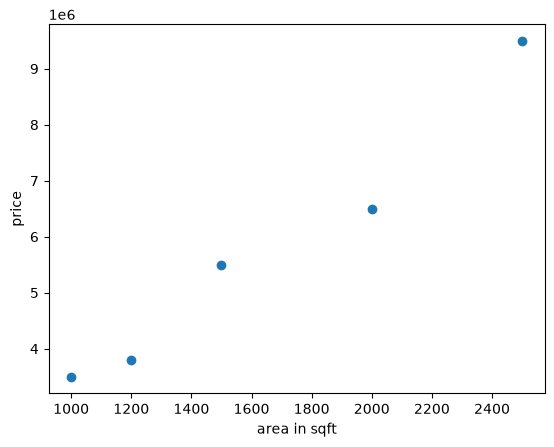

In [21]:
plt.scatter(df["area_sqft"], y)
plt.xlabel('area in sqft')
plt.ylabel('price')
plt.show()

In [30]:
from sklearn.model_selection import train_test_split

In [31]:
# Split the data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=50
)

In [35]:
print("Size of X_train", X_train.shape)
print("Size of X_test", X_test.shape)
print("Size of y_train", y_train.shape)
print("Size of y_test", y_test.shape)

Size of X_train (4, 4)
Size of X_test (1, 4)
Size of y_train (4,)
Size of y_test (1,)


In [36]:
from sklearn.linear_model import LinearRegression

In [37]:
# Createing the ML model instance
model = LinearRegression()

In [38]:
# Training the model using the training data X_train and y_train
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[ 3027.27, 72730.02, 208180.99,-102727. ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['area_sqft','bedrooms','bathrooms','house_age']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,6.327e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,3


In [39]:
y_pred=model.predict(X_test)

In [41]:
X_test

,area_sqft,bedrooms,bathrooms,house_age
3,2500,4,3,2


In [42]:
y_pred

array([8910907.99008364])

In [43]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [48]:
# Calculations
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R² Score: {r2:.2f}")

MAE: 589092.01
RMSE: 589092.01
R² Score: nan


C:\Users\DIO_PC\Documents\python_training\.mypracticeenv\Lib\site-packages\sklearn\metrics\_regression.py:1295: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)
